# 02 - Crescimento

**Pergunta central:** como evoluíram pedidos, vendas e ticket médio, e onde o negócio se concentra (categorias e estados)?

## 1. Configuração

Importa bibliotecas essenciais e configura atalhos para formatação de gráficos e números.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from pathlib import Path
from utils import br, pct, limpa, COR, COR_DESTAQUE, COR_CINZA, JANELA_INICIO as INICIO, JANELA_FIM as FIM, SEED

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)

PROCESSED = Path("../data/processed")
RAW = Path("../data/raw")
FIG = Path("../reports/figures")
TAB = Path("../reports/tabelas")

# Cria as pastas se não existirem
for pasta in (FIG, TAB):
    pasta.mkdir(parents=True, exist_ok=True)

# Janela de análise definida em utils.py (justificativa no notebook 01, seção 10)
STATUS_EXCLUIDOS = ["canceled", "unavailable"]


## 2. Carga e recorte do período

Lê a base tratada gerada no Notebook 01 convertendo as colunas de data.

In [2]:
colunas_data = [
    "order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
    "order_delivered_customer_date", "order_estimated_delivery_date",
]
base = pd.read_csv(PROCESSED / "base_pedidos.csv", parse_dates=colunas_data)
base["mes_compra"] = base["order_purchase_timestamp"].dt.to_period("M")

janela = base[(base["mes_compra"] >= INICIO) & (base["mes_compra"] <= FIM)].copy()

# Pedidos que realmente geraram venda: com itens e sem cancelamento/indisponibilidade
validos = janela[
    ~janela["order_status"].isin(STATUS_EXCLUIDOS) & janela["qtd_itens"].notna()
].copy()

print(f"Pedidos na base toda:            {br(len(base))}")
print(f"Pedidos no período {INICIO} a {FIM}: {br(len(janela))}")
print(f"  - cancelados/indisponíveis:    {br(janela['order_status'].isin(STATUS_EXCLUIDOS).sum())}")
print(f"  - sem itens:                   {br(janela['qtd_itens'].isna().sum())}")
print(f"Pedidos válidos (usados abaixo): {br(len(validos))}")

Pedidos na base toda:            99.441
Pedidos no período 2017-01 a 2018-08: 99.092
  - cancelados/indisponíveis:    1.182
  - sem itens:                   739
Pedidos válidos (usados abaixo): 97.905


## 3. Evolução mensal: pedidos, GMV e ticket médio

Agrupa os dados por mês de compra (mes_compra) para calcular métricas cruciais: pedidos, GMV e ticket médio.

In [3]:
mensal = validos.groupby("mes_compra").agg(
    pedidos=("order_id", "count"),
    clientes=("customer_unique_id", "nunique"),
    gmv=("receita_produtos", "sum"),
    frete=("frete", "sum"),
)
mensal["ticket_medio"] = mensal["gmv"] / mensal["pedidos"]
mensal["frete_pct_gmv"] = mensal["frete"] / mensal["gmv"]
mensal["var_mensal_pedidos"] = mensal["pedidos"].pct_change()

mensal.round(3)

,pedidos,clientes,gmv,frete,ticket_medio,frete_pct_gmv,var_mensal_pedidos
mes_compra,,,,,,,
2017-01,787,753,"120,098.27","16,845.19",152.60,0.14,NaN
2017-02,1718,1693,"244,959.35","38,602.34",142.58,0.16,1.18
2017-03,2617,2577,"368,341.32","57,276.64",140.75,0.15,0.52
2017-04,2377,2345,"353,842.98","52,005.63",148.86,0.15,-0.09
2017-05,3640,3569,"503,159.19","79,551.64",138.23,0.16,0.53
2017-06,3205,3142,"429,916.61","69,735.63",134.14,0.16,-0.12
2017-07,3946,3872,"492,287.30","86,466.43",124.76,0.18,0.23
2017-08,4272,4191,"568,245.79","93,657.73",133.02,0.17,0.08
2017-09,4227,4154,"621,415.91","95,686.81",147.01,0.15,-0.01


### 3.1 O crescimento continuou em 2018?
Compara os mesmos meses (jan a ago) de 2017 e 2018, para eliminar o efeito de sazonalidade.

In [4]:
def jan_ago(ano):
    m = mensal.loc[f"{ano}-01":f"{ano}-08"]
    return m["pedidos"].sum(), m["gmv"].sum()


p17, g17 = jan_ago(2017)
p18, g18 = jan_ago(2018)

print("Jan-Ago/2017 -> Jan-Ago/2018")
print(f"  Pedidos: {br(p17)} -> {br(p18)}  ({(p18 / p17 - 1):+.0%})")
print(f"  GMV:     R$ {br(g17 / 1e6, 1)} mi -> R$ {br(g18 / 1e6, 1)} mi  ({(g18 / g17 - 1):+.0%})")
print(f"  Ticket médio: R$ {br(g17 / p17, 2)} -> R$ {br(g18 / p18, 2)}")

ped_jan18 = mensal.loc["2018-01", "pedidos"]
ped_ago18 = mensal.loc["2018-08", "pedidos"]
print(f"\nDentro de 2018: jan = {br(ped_jan18)} pedidos | ago = {br(ped_ago18)} pedidos ({ped_ago18 / ped_jan18 - 1:+.0%})")

Jan-Ago/2017 -> Jan-Ago/2018
  Pedidos: 22.562 -> 53.530  (+137%)
  GMV:     R$ 3,1 mi -> R$ 7,3 mi  (+138%)
  Ticket médio: R$ 136,55 -> R$ 137,14

Dentro de 2018: jan = 7.187 pedidos | ago = 6.421 pedidos (-11%)


### 3.2 Gráfico: pedidos por mês

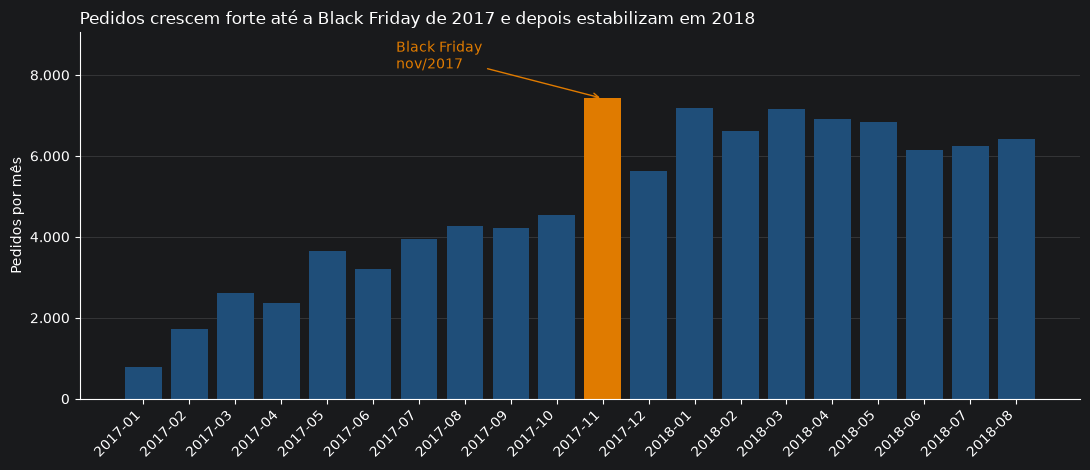

In [5]:
x = mensal.index.astype(str).tolist()
cores = [COR_DESTAQUE if m == "2017-11" else COR for m in x]

fig, ax = plt.subplots(figsize=(11, 4.8))
ax.bar(x, mensal["pedidos"], color=cores)
ax.set_xticks(range(len(x)))
ax.set_xticklabels(x, rotation=45, ha="right")
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: br(v)))
ax.set_ylabel("Pedidos por mês")
ax.set_ylim(top=mensal["pedidos"].max() * 1.22)

if "2017-11" in x:
    i = x.index("2017-11")
    v = mensal["pedidos"].iloc[i]
    ax.annotate("Black Friday\nnov/2017", xy=(i, v), xytext=(i - 4.5, mensal["pedidos"].max() * 1.10),
                arrowprops=dict(arrowstyle="->", color=COR_DESTAQUE), color=COR_DESTAQUE, fontsize=10)

ax.set_title("Pedidos crescem forte até a Black Friday de 2017 e depois estabilizam em 2018", loc="left", fontsize=12)
limpa(ax)
plt.tight_layout()
plt.savefig(FIG / "01_pedidos_por_mes.png", dpi=150)
plt.show()

### 3.3 Gráfico: GMV e ticket médio

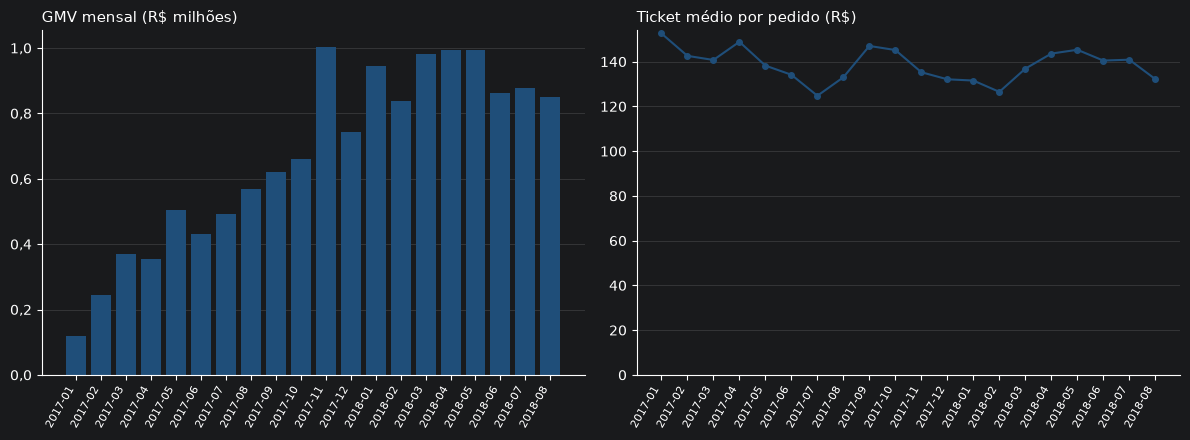

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].bar(x, mensal["gmv"] / 1e6, color=COR)
axes[0].set_title("GMV mensal (R$ milhões)", loc="left", fontsize=11)
axes[0].yaxis.set_major_formatter(FuncFormatter(lambda v, _: br(v, 1)))

axes[1].plot(x, mensal["ticket_medio"], color=COR, marker="o", markersize=4)
axes[1].set_title("Ticket médio por pedido (R$)", loc="left", fontsize=11)
axes[1].yaxis.set_major_formatter(FuncFormatter(lambda v, _: br(v)))
axes[1].set_ylim(bottom=0)

for ax in axes:
    ax.set_xticks(range(len(x)))
    ax.set_xticklabels(x, rotation=60, ha="right", fontsize=8)
    limpa(ax)

plt.tight_layout()
plt.savefig(FIG / "02_gmv_e_ticket_medio.png", dpi=150)
plt.show()

## 4. Categorias: onde está o dinheiro?

Cruza a tabela de itens com a de produtos e a tabela de tradução de categorias

In [7]:
itens = pd.read_csv(RAW / "olist_order_items_dataset.csv", usecols=["order_id", "product_id", "price", "freight_value"])
produtos = pd.read_csv(RAW / "olist_products_dataset.csv", usecols=["product_id", "product_category_name"])
trad = pd.read_csv(RAW / "product_category_name_translation.csv")

itens = itens[itens["order_id"].isin(validos["order_id"])]
n_antes = len(itens)

itens = itens.merge(produtos, on="product_id", how="left").merge(trad, on="product_category_name", how="left")
assert len(itens) == n_antes, "Join de categorias duplicou itens!"

# Categorias sem tradução ficam com o nome em português; produtos sem categoria viram 'sem_categoria'
itens["categoria"] = (
    itens["product_category_name_english"]
    .fillna(itens["product_category_name"])
    .fillna("sem_categoria")
)
print(f"Itens analisados: {br(len(itens))} | categorias distintas: {itens['categoria'].nunique()}")

Itens analisados: 111.752 | categorias distintas: 74


In [8]:
cat = (
    itens.groupby("categoria")
    .agg(gmv=("price", "sum"), itens=("price", "size"))
    .sort_values("gmv", ascending=False)
)
cat["participacao"] = cat["gmv"] / cat["gmv"].sum()
cat["participacao_acum"] = cat["participacao"].cumsum()

n80 = int((cat["participacao_acum"] < 0.80).sum() + 1)
print(f"{n80} de {len(cat)} categorias concentram 80% do GMV")
print(f"Top 3 categorias: {cat['participacao'].head(3).sum():.0%} do GMV")
cat.head(10).round(3)

18 de 74 categorias concentram 80% do GMV
Top 3 categorias: 26% do GMV


,gmv,itens,participacao,participacao_acum
categoria,,,,
health_beauty,"1,251,145.54",9585,0.09,0.09
watches_gifts,"1,194,824.97",5965,0.09,0.18
bed_bath_table,"1,035,485.07",11089,0.08,0.26
sports_leisure,"977,728.77",8573,0.07,0.33
computers_accessories,"902,922.70",7760,0.07,0.40
furniture_decor,"721,584.27",8229,0.05,0.45
housewares,"625,538.73",6903,0.05,0.50
cool_stuff,"619,724.39",3772,0.05,0.55
auto,"585,177.48",4195,0.04,0.59


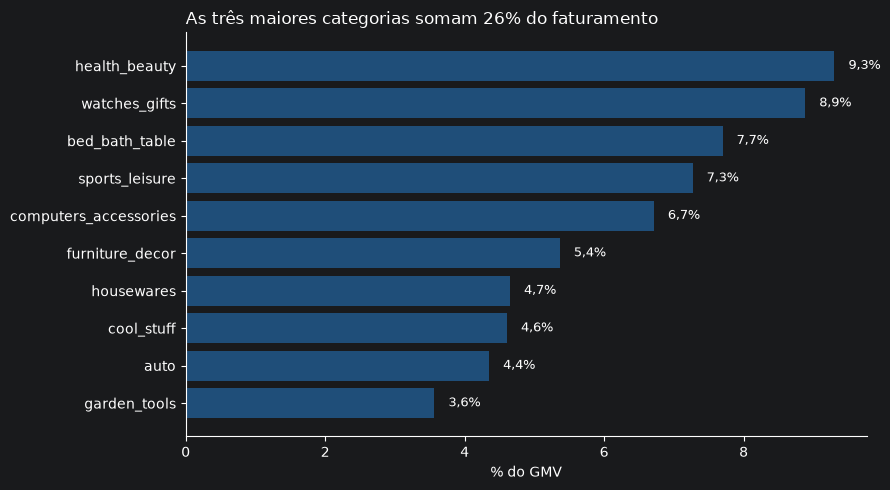

In [9]:
top = cat.head(10).iloc[::-1]

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top.index, top["participacao"] * 100, color=COR)
for i, v in enumerate(top["participacao"] * 100):
    ax.text(v + 0.2, i, f"{br(v, 1)}%", va="center", fontsize=9)
ax.set_xlabel("% do GMV")
ax.set_title("As três maiores categorias somam 26% do faturamento", loc="left", fontsize=12)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.savefig(FIG / "03_top_categorias.png", dpi=150)
plt.show()

## 5. Estados: onde estão os clientes (e o custo do frete)

Agrupa as vendas por estado do cliente (customer_state) para calcular a participação nos pedidos, o ticket médio e, crucialmente, o frete como percentual do valor dos produtos.

In [10]:
uf = validos.groupby("customer_state").agg(
    pedidos=("order_id", "count"),
    gmv=("receita_produtos", "sum"),
    frete=("frete", "sum"),
)
uf["part_pedidos"] = uf["pedidos"] / uf["pedidos"].sum()
uf["ticket_medio"] = uf["gmv"] / uf["pedidos"]
uf["frete_pct_gmv"] = uf["frete"] / uf["gmv"]
uf = uf.sort_values("pedidos", ascending=False)

print(f"Top 3 estados: {uf['part_pedidos'].head(3).sum():.0%} dos pedidos")
print(f"Maior estado ({uf.index[0]}): {uf['part_pedidos'].iloc[0]:.0%} dos pedidos")
uf.head(10).round(3)

Top 3 estados: 67% dos pedidos
Maior estado (SP): 42% dos pedidos


,pedidos,gmv,frete,part_pedidos,ticket_medio,frete_pct_gmv
customer_state,,,,,,
SP,41021,"5,150,778.70","712,453.96",0.42,125.56,0.14
RJ,12654,"1,802,436.24","303,113.40",0.13,142.44,0.17
MG,11457,"1,568,855.98","268,790.09",0.12,136.93,0.17
RS,5395,"739,357.46","134,277.30",0.06,137.04,0.18
PR,4962,"674,867.55","116,834.34",0.05,136.01,0.17
SC,3590,"516,340.22","89,182.76",0.04,143.83,0.17
BA,3340,"506,214.78","99,698.54",0.03,151.56,0.20
DF,2114,"299,842.68","50,284.42",0.02,141.84,0.17
ES,2014,"272,614.34","49,399.55",0.02,135.36,0.18


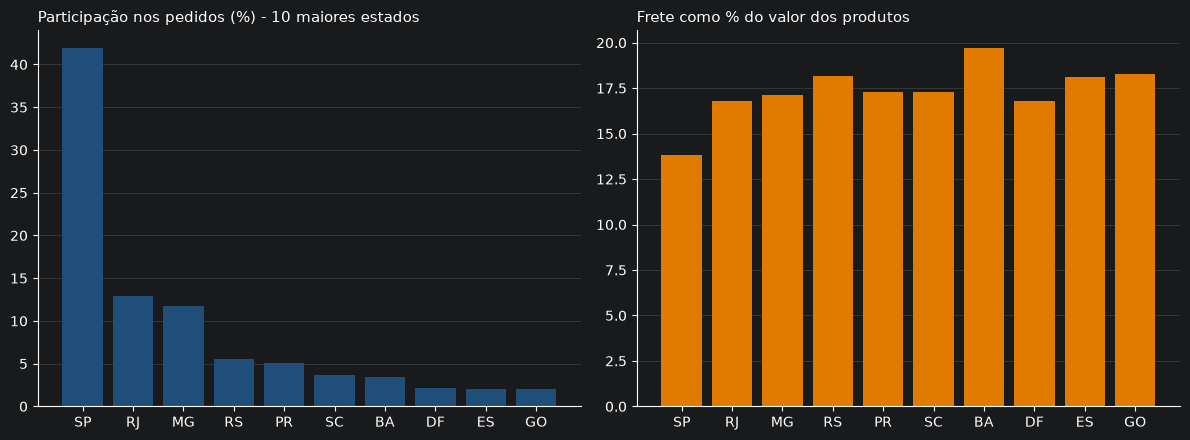

In [11]:
top_uf = uf.head(10)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].bar(top_uf.index, top_uf["part_pedidos"] * 100, color=COR)
axes[0].set_title("Participação nos pedidos (%) - 10 maiores estados", loc="left", fontsize=11)

axes[1].bar(top_uf.index, top_uf["frete_pct_gmv"] * 100, color=COR_DESTAQUE)
axes[1].set_title("Frete como % do valor dos produtos", loc="left", fontsize=11)

for ax in axes:
    limpa(ax)

plt.tight_layout()
plt.savefig(FIG / "04_estados_pedidos_e_frete.png", dpi=150)
plt.show()

## 6. Salvar as tabelas de apoio

In [12]:
mensal.to_csv(TAB / "mensal.csv")
cat.to_csv(TAB / "categorias.csv")
uf.to_csv(TAB / "estados.csv")
print("Tabelas salvas em", TAB)
print("Gráficos salvos em", FIG)

Tabelas salvas em ..\reports\tabelas
Gráficos salvos em ..\reports\figures
